# A 2-stage structured data extraction (SDE) cascade: cheap → verify → reasoning

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/sde_cascade/cascade_cookbook.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/sde_cascade/cascade_cookbook.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **No API key needed.** The code downloads this cookbook's saved answers, so
> *Run all* replays every TypeSafe call from them. It needs no TypeSafe account
> and costs nothing. To call the API yourself, set `TYPESAFE_API_KEY` and
> `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/sde_cascade).

- Overview
  - big reasoning models turn text into correct structured data, but are slow and expensive
  - small models are cheap, but make mistakes
  - a *cascade* runs the small model first and pays for the big one only when a check
    flags the small model's answer
  - the models we use:
    - rung 0 (cheap):
      [`gpt-6-luna`](https://developers.openai.com/api/docs/models/gpt-6-luna)
    - rung 1 (reasoning):
      [`gpt-6.1-sol`](https://developers.openai.com/api/docs/models/gpt-6.1-sol) with
      `reasoning_effort="high"`
    - verifier: `jev-1.14.0`
- Algorithm
  1. **Answer** with the cheap model, as a JSON object that matches a schema.
  2. **Verify** with **Jev**: ask yes/no questions ("Noul questions") about the answer, one
     per rule it must follow, such as "does this time overlap someone's meeting?"; each
     returns P(the rule is broken).
  3. **Escalate** to the reasoning model if the answer fails the schema or a rule check
     fires; otherwise keep the cheap answer.

## Setup

- install the dependencies:

```bash
pip install openai jsonschema ipython matplotlib pandas 'cooksafe>=0.3.0,<0.4.0'
```

- then set `OPENAI_API_KEY` and `TYPESAFE_API_KEY` in your environment

In [ ]:
%pip install -q 'openai' 'jsonschema' 'typesafe-sdk>=0.7.0' 'ipython' 'matplotlib' 'pandas' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
import json
import os
import re
import urllib.request
from pathlib import Path

import jsonschema
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cooksafe import JsonCache, make_playground_link
from IPython.display import Markdown, display
from openai import OpenAI
from typesafe_sdk import Noul, NoulCriteria, TypeSafeClient

CHEAP = "gpt-6-luna"  # rung 0: cheap + fast
STRONG = "gpt-6.1-sol-high"  # rung 1: gpt-6.1-sol with reasoning_effort="high"
CONFIGS = {
    CHEAP: {"model": "gpt-6-luna"},
    STRONG: {"model": "gpt-6.1-sol", "reasoning_effort": "high"},
}
TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
FIRE_T = 0.7  # escalate if any rule's P(broken) exceeds this; also the "<== FIRES" display marker

# keyless kernels replay the cache
oai = OpenAI(api_key=os.environ.get("OPENAI_API_KEY", "cache-only"))

ts = TypeSafeClient(api_key=os.environ.get("TYPESAFE_API_KEY", "cache-only"), timeout=30.0)

## Step 1: the data

- `example.json` holds one task from the calendar set of
  [NATURAL PLAN](https://github.com/google-deepmind/natural-plan): the busy times of three
  people on one work day, and a one-hour meeting to fit around them
- the code below downloads it from typesafe-public-examples unless it is already on disk

In [ ]:
EXAMPLE = Path("example.json")
EXAMPLE_URL = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/sde_cascade/example.json"
)
if not EXAMPLE.exists():
    urllib.request.urlretrieve(EXAMPLE_URL, EXAMPLE)
task = json.loads(EXAMPLE.read_text())["prompt_0shot"]

print(task.split("TASK:")[-1].replace("SOLUTION:", "").strip())

You need to schedule a meeting for Joan, Theresa and Shirley for one hour between the work hours of 9:00 to 17:00 on Monday. 

Here are the existing schedules for everyone during the day: 
Joan has meetings on Monday during 11:00 to 11:30, 12:30 to 13:00; 
Theresa has meetings on Monday during 12:00 to 12:30, 15:00 to 15:30; 
Shirley has meetings on Monday during 9:30 to 10:30, 11:00 to 12:00, 13:00 to 14:00, 15:30 to 16:30; 

Find a time that works for everyone's schedule and constraints.


- Every fact the answer depends on is in the text, but the answer itself isn't: the model
  has to work out a free hour from the busy times
- Shirley has four meetings, so only one full hour of the day is free for all three

## Step 2: answer with the cheap model

- the prompt ends with a JSON Schema for the answer: a day, a start time and an end time
- the model reads the schema in the prompt and replies with plain text that we parse. We
  don't use structured outputs, which would force valid JSON and hide the rare answer that
  breaks the schema

In [ ]:
TIME = {"type": "string", "pattern": "^([01][0-9]|2[0-3]):[0-5][0-9]$"}
SCHEMA = {
    "type": "object",
    "properties": {
        "day": {"type": "string", "enum": ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"], "description": "the day of the meeting"},
        "start_time": TIME | {"description": "when the meeting starts, 24-hour HH:MM"},
        "end_time": TIME | {"description": "when the meeting ends, 24-hour HH:MM"},
    },
    "required": ["day", "start_time", "end_time"],
    "additionalProperties": False,
}
FORMAT_LINE = "Return ONLY a JSON object matching this JSON Schema:\n" + json.dumps(SCHEMA, indent=2)


def prompt_for(task: str) -> str:
    """The task's prompt with the schema placed just before its closing SOLUTION:."""
    return re.sub(r"SOLUTION:\s*$", FORMAT_LINE + "\nSOLUTION: ", task.rstrip())


# LLM and TypeSafe calls are cached in CACHE, so a re-run reuses earlier answers instead of
# calling the APIs again.

EXAMPLES_URL = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/sde_cascade"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        urllib.request.urlretrieve(f"{EXAMPLES_URL}/{name}", path)
    return path


CACHE = Path("sde_cascade_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE)


@json_cache
def ask(config: str, prompt: str) -> dict:
    r = oai.chat.completions.create(messages=[{"role": "user", "content": prompt}], **CONFIGS[config])
    return {"text": r.choices[0].message.content, "in": r.usage.prompt_tokens, "out": r.usage.completion_tokens}


def parse(text: str) -> dict | None:
    """The answer as a record, or None if it isn't a JSON object matching ``SCHEMA``. The prompt
    asks for ONLY a JSON object, so parse the reply as-is -- no regex fishing a substring out of
    a malformed reply. A reply that fails either check escalates: the safe direction."""
    try:
        record = json.loads(text)
    except ValueError:
        return None
    return record if jsonschema.Draft202012Validator(SCHEMA).is_valid(record) else None


cheap_text = ask(CHEAP, prompt_for(task))["text"]
cheap_record = parse(cheap_text)
print("cheap answer:", cheap_text)
print("\nschema-valid:", cheap_record is not None)

cheap answer: {"day":"Monday","start_time":"10:30","end_time":"11:30"}

schema-valid: True


- The answer is **schema-valid** (the line above prints `True`), yet it's wrong:
  - Monday 10:30-11:30 overlaps Joan's meeting at 11:00 and Shirley's at 11:00
  - a JSON-Schema check can't see this. A cheap model produces confident,
    schema-satisfying mistakes of this kind, and catching them is the job of a semantic
    verifier

## Step 3: verify with Jev

- the verifier is **Jev**; we ask it one `Noul` question per rule the answer must follow,
  each framed so that `true` = the rule is broken (escalate)
- Jev returns a calibrated `noul` = `P(true)` per question, in one system_one call
- the state holds the task and the cheap model's record; Jev never sees a correct answer
- **The TypeSafe Way: Decomposition**
  - we split the check in code into narrow questions, one per rule, never one question
    about the whole answer
  - a flag then names the rule that broke, and each question can be reworded or
    re-thresholded on its own
  - a single "is this answer right?" returns one score that cannot say what went wrong
  - see
    [Decompose the questions](/concepts/how-to-build-with-system-one#decompose-the-questions)
  - ![this is the way](https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/sde_cascade/this_is_the_way.jpg)

In [ ]:
RULES = {
    "busy_conflict": "Does the meeting time in the `answer` overlap a time when any participant in the `task` is busy?",
    "outside_hours": "Is the meeting time in the `answer` outside the work hours or the days the `task` allows?",
    "breaks_preference": "Does the meeting time in the `answer` break a preference stated in the `task`, such as a participant who would rather not meet on a certain day or before or after a certain time?",
    "not_earliest": "Does the `task` ask for the earliest availability, and is there an earlier time that works for every participant?",
    "wrong_length": "Is the meeting in the `answer` a different length from the one the `task` asks for?",
    "no_single_time": "Does the `answer` fail to propose exactly one day and one start and end time?",
}
CHECKS = {
    rule: Noul(
        instructions=question,
        criteria=NoulCriteria(true="the answer breaks this rule", false="the answer follows this rule"),
    )
    for rule, question in RULES.items()
}


@json_cache
def verify(state_json: str, model: str) -> dict[str, float]:
    """Ask every rule question about one answer in one TypeSafe call; return ``{rule: P(broken)}``."""
    questions = {k: q.model_dump(mode="json", exclude_none=True) for k, q in CHECKS.items()}
    answers = ts.system_one(state=json.loads(state_json), questions=questions, model=model).answers
    return {rule: ans.noul for rule, ans in answers.items()}

In [ ]:
state = {"task": task, "answer": cheap_record}
checks = verify(json.dumps(state), model=TYPESAFE_MODEL)
playground_link = make_playground_link(state, {k: q.model_dump(mode="json", exclude_none=True) for k, q in CHECKS.items()})
display(Markdown(f"🔗 [Open this verification in the TypeSafe playground]({playground_link})"))

print(f"{'rule':<20}{'P(broken)':>10}")
print("-" * 30)
for rule, p in sorted(checks.items(), key=lambda c: -c[1]):
    flag = "  <== FIRES" if p > FIRE_T else ""
    print(f"{rule:<20}{p:>10.2f}{flag}")

rule                 P(broken)
------------------------------
busy_conflict             0.97  <== FIRES
not_earliest              0.25
wrong_length              0.17
breaks_preference         0.09
no_single_time            0.07
outside_hours             0.04


🔗 [Open this verification in the TypeSafe playground](https://console.typesafe.ai/playground#share/N4IgJg9gxgrgtgUwHYBcAqCAeKQC4AEIwAOiCgIYDOA1qQaQJoQz7kBOCrS+WADgmxSshlKAAsEYGABsAlkgDm+RAhTyFlAHT4mLdpwWyAbslb4AZggDu+KBCSUUbcvJSV89-Cgk9Msx+r4ohJS0pwQ5jzk4vi87GpQsnGoADRePipqivhSzmr2aeRIYLEQlJSyAEbSAJ5BEIixHJYcSFAI7p7enJmBaojaAHIQKJzdHL7+bmaUENIw+dze5EJWEGzU7lay3pMB2cGSMuGRCCZsdXGCsonJKNoAEgKc+maWNljkcLxhXlSbXBKs3mi0ouGIxCQEKQaAAggBlADSBF0+CQCEkXggQXER1+5GUGKySnM63wACkIEU0mgJBxKASiiV4WJZGwwnVSWwPOj8GJmNzKqorBilj41hs+QLOpEAJy4AAMCqx+AAjAB2RXKzwAWXsYHINW00OhTwmr26e2JOJCx3cXJ45xq9k4uT6PgNNXokMpRT5VEJqnUnW4euKhpyMDYgVVqq1KtjuAAzAq0qqAEzJ5UobGqpNagDc+GhtOeDP97l6ihD+DDnsj0eyGfjObVmZTaYArC3c92U0XoSy2RyK4HiTW6xG3dl5SmEwqs2m40qE5mlWn8yvW6qACxartZhMANizA8h0IAYvISgT+mMxCt8BKAQ6zgJneiAOTuQ6hF7FWx7EcZxXC0YtIXhAB5AAZABVNAAElIMGegQDSUgikoEU2DofASHAQ1cNIScalIdCQEceIAH07yIkBVQXFMyOLEBkDAGjZEQOjEyYkAAF8+LQwheDYBpeDcDBsDwQh8MqGBKBqKi7CQcw5CgFBcPwlAan4OikGYaRmNIeRgJgdTZCAuiABEIA6dIeiJPpOM4eR7PwAADTDsPcjxzmkcheDMO8nwkbgikueIbiSIohFcy13IoGgfP8fA5IUgB+IyQCgaNRmjchNNIJwYAQOjLS8gRUo4cgAW8FK2GOLLzHIaRKFK6Sip8CruVJaRpAgKx3Dq9wGrCUgBPI5g3FkMAECo-ko0oQqyB09rUP0mQspM4rzMsjqQAQoaMkc7JgrinxPIcbyPAWCpZrc58pUWjxuUtT0js4BL-h8lr+sGzKhNIHKdgEWQCukrSGrWljyquyrKmq2rWRGxrAZAZrWuhzr-ywyrer+o76tRiaWIRhAasoKiRIQFpkHaZbtN0-aNsMtHtoa3aHGs2yPrHJzGnOz7up8smarManabaThKNGEpBY8xLqHctJKDMsRWHcAkrgSaLUBC7E1hkEo8jpNERjHHkzHaQQXG4esySFLlwm5chzDyq2BAoOLnIB8jgbysGGahsqurhwVEcJlGxrRjG2pDnHsIsOYCfSIno5J0h9JQKjyfZWQOg0iGitWvSDK2hwdtBbm7PixWfpoJPXp8XO5AL1gjBcfzKlkORtMKACUvGf8ojzyrguWVZ1hfMk3wuWJItuGLfZY-3QfBghIZK+OuFx8PyaRtP2vI2OsbIUPd6TvqBsj-BRvajOQCsUTFCosJFG8BmS+Zsu2Yrjmq-2odNyVYlDy0urvH6ORZDmElkIN+ChdjmFEnANyLo3JfSShraebBl5A1ymvIOW99qwwvqLA+Ucj4sRPtvbql8U7DVvsTPi5F9JUQqIoMIHEuJFxWkzdaP9yLszMgA1CNka4XWFhYTuKoRIQF4GUTgnx1K1B5K6CMTJVFBAoIIQEPAAJ3lwdlfB+VCGnxIYnMhN875NRanHYh59E742vqnCh40BJCRAAFWQAA1AQFR7DSRAEYVU-EgA)

- Only the broken rule scores high:
  - `busy_conflict` fires at 0.97
  - every other rule stays at 0.25 or below

## Step 4: decide whether to escalate

- escalate if the answer failed the schema check, or if *any* rule's probability exceeds
  `FIRE_T`
- this is a `max`-style check, not a mean, so one confident red flag is enough instead of
  being averaged into silence
- one threshold works only if the questions separate, scoring high on broken rules and low
  on kept ones, as in Step 3
- the verifier has to cost far less than the reasoning rung, or the cascade saves nothing

In [ ]:
fired = {rule: p for rule, p in checks.items() if p > FIRE_T}
escalate = cheap_record is None or bool(fired)

print(f"check (threshold {FIRE_T}): {'ESCALATE' if escalate else 'ACCEPT cheap answer'}")
for rule, p in sorted(fired.items(), key=lambda c: -c[1]):
    print(f"  fired: {rule}  (P={p:.2f})")

check (threshold 0.7): ESCALATE
  fired: busy_conflict  (P=0.97)


## Step 5: escalate to the reasoning model

Since a check fired, we pay for the strong model (`gpt-6.1-sol`,
`reasoning_effort="high"`)

In [ ]:
final_record = parse(ask(STRONG, prompt_for(task))["text"]) if escalate else cheap_record

print("cheap     :", json.dumps(cheap_record))
print("reasoning :", json.dumps(final_record))

cheap     : {"day": "Monday", "start_time": "10:30", "end_time": "11:30"}
reasoning : {"day": "Monday", "start_time": "14:00", "end_time": "15:00"}


- **The improvement**
  - The reasoning model proposes Monday 14:00-15:00, which is free for all three people
  - The cascade paid for the reasoning model on this task only because the verifier
    flagged it

## Step 6: the cascade on 1,000 tasks

- One example shows how the loop runs. To see whether it pays, we run it on many tasks and
  plot cost against quality
- A cascade pays when the cheap model is right most of the time and its mistakes break
  rules a check can see. Scheduling a meeting fits:
  - **task:** the 1,000 calendar-scheduling tasks of
    [NATURAL PLAN](https://github.com/google-deepmind/natural-plan). Each gives the busy
    times of 2 to 7 people across 1 to 5 work days, how long the meeting should be, and
    sometimes a preference, such as "would rather not meet on Monday". The model proposes
    one time that works for everyone
  - **prompt:** each task's text, ending with the JSON Schema from Step 2
  - **models:** `gpt-6-luna` with default reasoning is the cheap rung, and `gpt-6.1-sol`
    with `reasoning_effort="high"` is the strong one. Both answer every task, so we know
    what each does alone
  - **checks:** the six rule questions from Step 3. A task's flag is the highest of the
    six, or 1 when luna's answer fails the schema check
  - **cascade:** a task goes to sol-high when its flag is above the threshold. Its cost is
    luna plus Jev, plus sol-high when it goes on
  - **grading:** an answer works if it is JSON that matches the schema and proposes one of
    the task's valid times. Some tasks admit more than one valid time, which we added to
    NATURAL PLAN's answer key; the full key is in `calendar_answers.json`. Grading only
    scores answers and plays no part in the cascade
- [`calendar_sweep.py`](https://github.com/typesafe-ai/typesafe-public-examples/blob/main/cookbooks/sde_cascade/calendar_sweep.py)
  made these calls and wrote one row per task to `calendar_results.csv`. The code below
  draws the chart from that file and calls nothing
- Numbers below came from `jev-1.14.0` on 2026-11-05

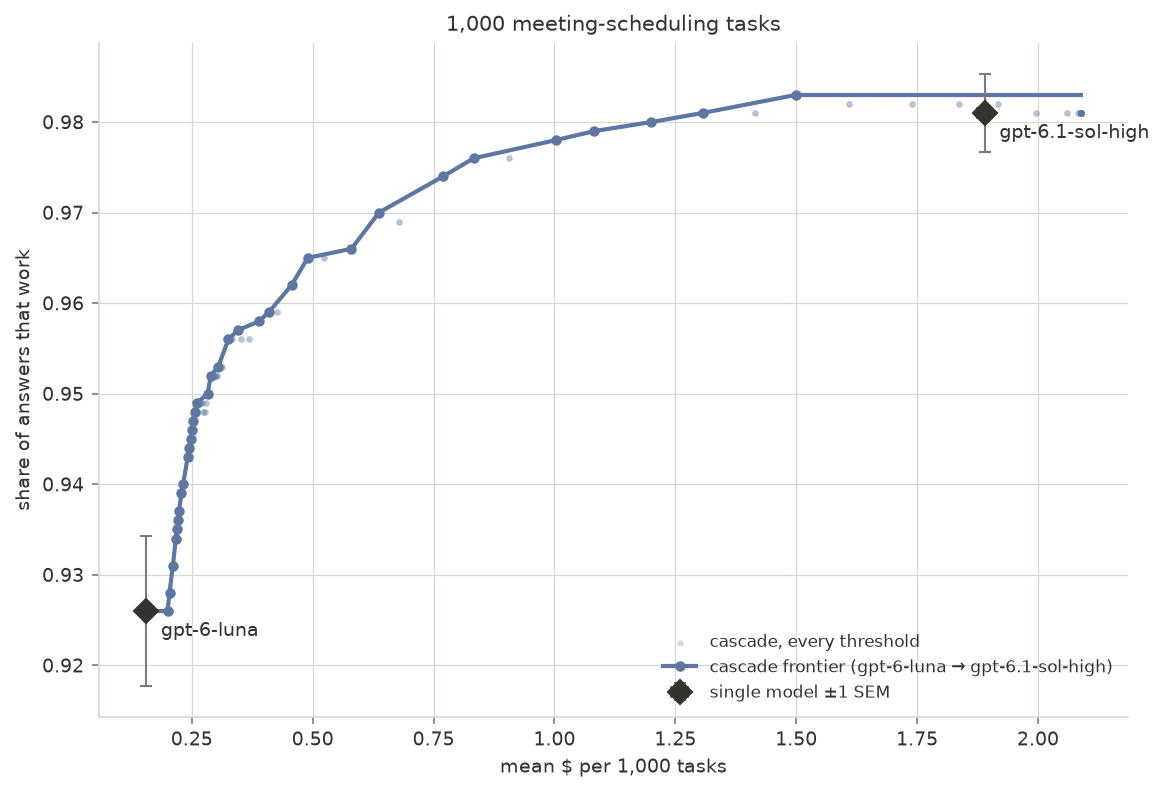

In [ ]:
RESULTS = Path("calendar_results.csv")
RESULTS_URL = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/sde_cascade/calendar_results.csv"
)
if not RESULTS.exists():
    urllib.request.urlretrieve(RESULTS_URL, RESULTS)
tasks = pd.read_csv(RESULTS)  # one row per task: each model's cost, whether its answer works, Jev's flag


def cascade_at(t: float) -> dict:
    """Mean cost per 1,000 tasks and share of answers that work when tasks flagged above t escalate."""
    escalate = tasks["flag"] > t
    cost = tasks["cheap_cost"] + tasks["check_cost"] + escalate * tasks["strong_cost"]
    works = tasks["strong_works"].where(escalate, tasks["cheap_works"])
    return {"threshold": t, "cost": 1000 * cost.mean(), "works": works.mean(), "escalated": escalate.mean()}


cascade = pd.DataFrame([cascade_at(t) for t in np.linspace(0, 1, 201)])
frontier = cascade.sort_values(["cost", "works"], ascending=[True, False])
frontier = frontier[frontier["works"] > frontier["works"].cummax().shift(fill_value=-1)]
singles = pd.DataFrame(
    {
        name: {
            "cost": 1000 * tasks[f"{rung}_cost"].mean(),
            "cost_sem": 1000 * tasks[f"{rung}_cost"].sem(),
            "works": tasks[f"{rung}_works"].mean(),
            "works_sem": tasks[f"{rung}_works"].sem(),
        }
        for name, rung in (("gpt-6-luna", "cheap"), ("gpt-6.1-sol-high", "strong"))
    }
).T

# The docs page shows the chart matching its light or dark theme; a notebook shows the light one.
PALETTES = {
    "light": {"surface": "#ffffff", "ink": "#34342f", "muted": "#7c7c77", "grid": "#d8d8cf", "blue": "#5d76a2", "cloud": 0.25},
    "dark": {"surface": "#0d0a0f", "ink": "#fafafa", "muted": "#a1a1aa", "grid": "#3f3f46", "blue": "#8fa6d6", "cloud": 0.35},
}


def draw_chart(p: dict) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(8, 5.4), facecolor=p["surface"])
    ax.set_facecolor(p["surface"])
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(p["grid"])
    ax.tick_params(colors=p["muted"], labelcolor=p["ink"], labelsize=9)
    ax.grid(color=p["grid"], linewidth=0.6)
    ax.set_axisbelow(True)
    ax.scatter(cascade["cost"], cascade["works"], s=10, color=p["blue"], alpha=p["cloud"], lw=0,
               label="cascade, every threshold")
    ax.plot(frontier["cost"], frontier["works"], color=p["blue"], lw=2, marker="o", ms=4,
            label="cascade frontier (gpt-6-luna → gpt-6.1-sol-high)")
    first, last, luna = frontier.iloc[0], frontier.iloc[-1], singles.loc["gpt-6-luna"]
    if luna["cost"] < first["cost"]:  # luna alone sits left of the frontier: join it at luna's level
        ax.plot([luna["cost"], first["cost"]], [luna["works"]] * 2, color=p["blue"], lw=2)
    ax.plot([last["cost"], cascade["cost"].max()], [last["works"]] * 2, color=p["blue"], lw=2)  # past here, more spend buys nothing
    ax.errorbar(singles["cost"], singles["works"], xerr=singles["cost_sem"], yerr=singles["works_sem"], fmt="D",
                ms=8, color=p["ink"], ecolor=p["muted"], elinewidth=1, capsize=3, label="single model ±1 SEM")
    for name, row in singles.iterrows():
        ax.annotate(name, (row["cost"], row["works"]), xytext=(7, -12), textcoords="offset points", fontsize=9,
                    color=p["ink"])
    ax.set_xlabel("mean $ per 1,000 tasks", color=p["ink"], fontsize=9)
    ax.set_ylabel("share of answers that work", color=p["ink"], fontsize=9)
    ax.set_title("1,000 meeting-scheduling tasks", color=p["ink"], fontsize=10)
    ax.legend(fontsize=8, frameon=False, loc="lower right", labelcolor=p["ink"])
    plt.tight_layout()
    return fig


# The docs build sets COOKSAFE_RENDER and also draws the dark copy.
for theme in ("light", "dark") if os.environ.get("COOKSAFE_RENDER") else ("light",):
    fig = draw_chart(PALETTES[theme])
    display(fig, metadata={"theme": theme})
    plt.close(fig)

In [ ]:
print(singles[["cost", "works"]].round(3).to_string())
wrong = tasks["cheap_works"] == 0
print(f"\nluna is wrong on {wrong.sum()} tasks; {tasks.loc[wrong, 'schema_valid'].sum()} of those answers pass the schema check")
print()
print(pd.DataFrame([cascade_at(t) for t in (0.58, 0.29, 0.18, 0.16)]).round(3).to_string(index=False))

                   cost  works
gpt-6-luna        0.156  0.926
gpt-6.1-sol-high  1.890  0.981

luna is wrong on 74 tasks; 72 of those answers pass the schema check

 threshold  cost  works  escalated
      0.58 0.261  0.949      0.027
      0.29 0.490  0.965      0.133
      0.18 1.307  0.981      0.536
      0.16 1.500  0.983      0.641


- How to read it:
  - **black diamonds:** each model on its own, with ±1 SEM bars. Cost barely varies from
    task to task, so the cost bars are narrower than the markers
  - **blue points:** the cascade at every threshold. The line joins the points no other
    point beats on both cost and quality
- What it shows:
  - luna alone gets 92.6% of answers right at $0.16 per 1,000 tasks, and sol-high alone
    98.1% at $1.89
  - 72 of luna's 74 wrong answers pass the schema check, so only Jev's rule checks can
    catch them
  - sending the 3% of tasks Jev flags most to sol-high lifts the cascade to 94.9% for
    $0.26
  - sending 13% reaches 96.5% for $0.49, about a quarter of sol-high's cost
  - sending 54% matches sol-high, 98.1%, for $1.31. Past 64% (98.3% for $1.50), spending
    more buys nothing, which the flat line on the right shows
  - Jev's checks cost $0.04 per 1,000 tasks